# Verificacion de librerias

In [77]:
import matplotlib.pyplot as plt

In [78]:
import pandas as pd 

In [79]:
from sklearn import (
    preprocessing,
    ensemble,
    tree
)
from sklearn.metrics import (
    auc,
    confusion_matrix,
    roc_auc_score,
    roc_curve
)
from sklearn.model_selection import (
    StratifiedKFold,
    train_test_split
)
from yellowbrick.classifier import (
    ROCAUC,
    ConfusionMatrix
)
from yellowbrick.model_selection import LearningCurve

In [80]:
url = (
    "titanic3.xls"
)

url

'titanic3.xls'

In [81]:
def get_titanic_df():
    return pd.read_excel(url)
df = get_titanic_df()
orig_df =df

In [82]:
df.head()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


# Limpieza de datos

Algunos modelos funcionan mejor si los predictores son valores numericos como int y float

Algunos tienden a funcionar de forma mas deficiente con valores que no estan presente, NULL o NAN

In [83]:
df.dtypes

pclass         int64
survived       int64
name             str
sex              str
age          float64
sibsp          int64
parch          int64
ticket        object
fare         float64
cabin            str
embarked         str
boat          object
body         float64
home.dest        str
dtype: object

## shape

- Ayuda a conocer el número de filas y columnas del dataset
- Imprime una tupla con el formato (r, c) donde **r** representa el número de filas y **c** el número de columnas del dataset

In [84]:
df.shape

(1309, 14)

In [85]:
df.describe()

,pclass,survived,age,sibsp,parch,fare,body
count,1309.000000,1309.000000,1046.000000,1309.000000,1309.000000,1308.000000,121.000000
mean,2.294882,0.381971,29.881135,0.498854,0.385027,33.295479,160.809917
std,0.837836,0.486055,14.413500,1.041658,0.865560,51.758668,97.696922
min,1.000000,0.000000,0.166700,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,21.000000,0.000000,0.000000,7.895800,72.000000
50%,3.000000,0.000000,28.000000,0.000000,0.000000,14.454200,155.000000
75%,3.000000,1.000000,39.000000,1.000000,0.000000,31.275000,256.000000
max,3.000000,1.000000,80.000000,8.000000,9.000000,512.329200,328.000000


In [86]:
df.isnull().sum()

pclass          0
survived        0
name            0
sex             0
age           263
sibsp           0
parch           0
ticket          0
fare            1
cabin        1014
embarked        2
boat          823
body         1188
home.dest     564
dtype: int64

In [87]:
df.isnull()

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,False,False,False,False,False,False,False,False,False,False,False,False,True,False
1,False,False,False,False,False,False,False,False,False,False,False,False,True,False
2,False,False,False,False,False,False,False,False,False,False,False,True,True,False
3,False,False,False,False,False,False,False,False,False,False,False,True,False,False
4,False,False,False,False,False,False,False,False,False,False,False,True,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,False,False,False,False,False,False,False,False,False,True,False,True,False,True
1305,False,False,False,False,True,False,False,False,False,True,False,True,True,True
1306,False,False,False,False,False,False,False,False,False,True,False,True,False,True
1307,False,False,False,False,False,False,False,False,False,True,False,True,True,True


In [88]:
mask = df.isnull().any(axis=1)
mask.head()

0    True
1    True
2    True
3    True
4    True
dtype: bool

In [89]:
df[mask].body.head

<bound method NDFrame.head of 0         NaN
1         NaN
2         NaN
3       135.0
4         NaN
        ...  
1304    328.0
1305      NaN
1306    304.0
1307      NaN
1308      NaN
Name: body, Length: 1309, dtype: float64>

# Campos categoricos


si se aplica el metodo value_counts sobre una columna de tipo **object** , que tenga sospechas de ser categorica. Ayuda a conocer la cantidad de filas por tipo de columna.

---

por defecto, pandas ignora las columnas marcadas como vacias o con filas NaN, para incluirlas en el conteo se usa el parametro **dropna** en **False** (por defecto **dropna=True**)

In [90]:
df.sex.value_counts(dropna=False)

sex
male      843
female    466
Name: count, dtype: int64

In [91]:
df.embarked.value_counts(dropna=False)

embarked
S      914
C      270
Q      123
NaN      2
Name: count, dtype: int64

# Eliminacion de columnas


Podemos usar el metodo .drop de pandas para eliminar columnas que no aporten nada de valor o señales al modelo, como la columna nombre. Adicionalmente podemos eliminar las columnas que contengan informacion que pueda causar engaños al modelo como body y boat

In [92]:
df = df.drop(columns=[
    "name",
    "ticket",
    "body",
    "boat",
    "home.dest",
    "cabin"
])

In [93]:
df.head(3)

,pclass,survived,sex,age,sibsp,parch,fare,embarked
0,1,1,female,29.0000,0,0,211.3375,S
1,1,1,male,0.9167,1,2,151.5500,S
2,1,0,female,2.0000,1,2,151.5500,S


# Creando columnas

Para las columnas categoricas que quedaron, como **sex** y **embarked**, actualmente estan de tipo object, pero los modelos funcionan mejor con valores numericos. **pandas** cuenta con la funcion **get_dummies** para este caso

In [94]:
df = pd.get_dummies(df)

In [95]:
df.columns


Index(['pclass', 'survived', 'age', 'sibsp', 'parch', 'fare', 'sex_female',
       'sex_male', 'embarked_C', 'embarked_Q', 'embarked_S'],
      dtype='str')

## Colinealinidad

en el caso de sex_male y sex_female, son inversamente correlacionadas por lo que se puede ver como una redundancia. ### SI NO ES UNA ENTONCES ES LA OTRA

---
Podemos eliminar una de las columnas

In [96]:
df = df.drop(columns=["sex_male"])
df.columns

Index(['pclass', 'survived', 'age', 'sibsp', 'parch', 'fare', 'sex_female',
       'embarked_C', 'embarked_Q', 'embarked_S'],
      dtype='str')

Alternativamente podemos usar la misma funcion get_dummies de **pandas** con el parametro **drop_first=True**

In [97]:
df.columns

Index(['pclass', 'survived', 'age', 'sibsp', 'parch', 'fare', 'sex_female',
       'embarked_C', 'embarked_Q', 'embarked_S'],
      dtype='str')

# Separación del DataFrame en X e y

Hasta este momento el dataframe df, tiene mezclado todo el dataframe: features X y targets y, debemos separarlos

In [98]:
y = df.survived
X = df.drop(columns=["survived"])
X.head(3)

,pclass,age,sibsp,parch,fare,sex_female,embarked_C,embarked_Q,embarked_S
0,1,29.0000,0,0,211.3375,True,False,False,True
1,1,0.9167,1,2,151.5500,False,False,False,True
2,1,2.0000,1,2,151.5500,True,False,False,True


# Separación en datos de test y entrenamiento

Debemos separar los datos de X e Y en datos de entrenamiento y prueba, de modo que podamos hacer el entrenamiento y las pruebas en conjuntos diferentes, de otro modo no podemos saber que tan bien puede generalizar el modelo sobre datos que no ha visto en fase de entrenamiento

In [99]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Imputando valores faltantes


Queremos unicamente imputar valores numericos en los datos de entrenamiento para luego aplicar el imputer ya entrenado a para test


In [100]:
from sklearn.experimental import enable_iterative_imputer

In [101]:
from sklearn import impute

num_cols = [
    "pclass",
    "age",
    "sibsp",
    "parch",
    "fare",
    "sex_female"
]

In [102]:
imputer = impute.IterativeImputer()
imputed = imputer.fit_transform(X_train[num_cols])

In [103]:
X_train[num_cols] = imputed

In [104]:
imputed = imputer.transform(X_test[num_cols])
X_test[num_cols] = imputed

En el libro esta linea se muestra como

X_train.loc[:, num_cols] = imputed 

esto da error, es más facil hacer la asignación directa  como en este caso

# Estandarización

O preprocesamiento, es necesario para evitar que las columnas con escalas grandes sean tratadas como más importantes que otras columnas con escalas numericas mucho mas pequeñas. El proceso es, básicamente, asignar un valor de entre cero y una desviación estandar de 1.

Scikitlearn tiene una clase StandardScaler en el paquete preprocessing

In [105]:
from sklearn.preprocessing import StandardScaler

cols = [
    "age",
    "pclass",
    "sibsp",
    "fare"
]

In [106]:
sca = StandardScaler()
X_train[cols] = sca.fit_transform(X_train[cols])

In [107]:
X_test[cols] = sca.transform(X_test[cols])

## Nota de la interfaz StandardScaler

En versiones más modernas de scikitlearn,  StandardScaler se puede configurar su salida como un dataframe de pandas
```python
sca = StandardScaler().set_output(transform="pandas")
X_train = sca.fit_transform(X_train)
```


# Modelo baseline

Podemos crear un modelo base que nos ayude a tener un punto de patida y saber que esperar con modelos más avanzados

In [108]:
from sklearn.dummy import DummyClassifier

dm = DummyClassifier(strategy="stratified", random_state=42)
dm.fit(X_train, y_train)

dm.score(X_test, y_test)

0.4860050890585242

In [109]:
import numpy as np

preds = dm.predict(X_test)
print(np.unique(preds, return_counts=True))

(array([0, 1]), array([254, 139]))


In [110]:
from sklearn import metrics


metrics.precision_score(y_test, dm.predict(X_test), zero_division=0)

0.381294964028777

## Nota de version SKLEARN

el libro de **Matt Harrison** fue escrito con versiones de scikitlearn < 24, en este el constructor del **DummyClassifier** era stratified:

```python
from sklearn.dummy import DummyClassifier
dm = DummyClassifier(strategy="stratified")
```

en versiones actuales el parametro por defecto es "prior", para replicar el comportamiento del libro se debe establecer el parametro a stratified y random_state:

```python
from sklearn.dummy import DummyClassifier

dm = DummyClassifier(strategy="stratified", random_state=42)
```

# Aplicando varias familias de algoritmos

In [111]:
X_folds = pd.concat([X_train, X_test])
y_folds = pd.concat([y_train, y_test])

In [112]:
from sklearn import model_selection
from sklearn.dummy import DummyClassifier as DC
from sklearn.linear_model import LogisticRegression as LR
from sklearn.tree import DecisionTreeClassifier as DTC
from sklearn.neighbors import KNeighborsClassifier as KNNC
from sklearn.naive_bayes import GaussianNB as GNB
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier as RFC

In [113]:
import xgboost

In [114]:
from typing import List

ClassifiersModels: List = [DC, LR, DTC, KNNC, GNB, RFC, xgboost.XGBClassifier]

## Explicación

1. Primero importamos todos los modelos de clasificacion que queremos entrenar para evaluar
2. En un ciclo for los recorremos todos, para someterlos a validar y probar mediante cross_val_score de model_selection
3. Usamos un split de 10 en la clase KFold de model_selection usando roc_auc como metrica de desempeño
4. Imprimimos los resultados

In [115]:
for model in ClassifiersModels:
    cl = model()
    kfolds = model_selection.KFold(n_splits=10, shuffle=True, random_state=42)
    s = model_selection.cross_val_score(
        cl, X_folds, y_folds, scoring="roc_auc", cv=kfolds
    )
    print(
        f"{model.__name__:22} AUC: {s.mean():.3f} | STD: {s.std():.2f}"
    )

DummyClassifier        AUC: 0.500 | STD: 0.00
LogisticRegression     AUC: 0.841 | STD: 0.04
DecisionTreeClassifier AUC: 0.757 | STD: 0.02
KNeighborsClassifier   AUC: 0.827 | STD: 0.02
GaussianNB             AUC: 0.804 | STD: 0.04
RandomForestClassifier AUC: 0.846 | STD: 0.02
XGBClassifier          AUC: 0.853 | STD: 0.02


# Stacking


un clasificador Stacking es, en escencia, un estimador que toma la salida de otros clasificadores para generar una nueva predicción basado en esas salidas. Básicamente encadena salidas de modelos.

---

Actualmente existen dos formas de usar stacking, de forma nativa con la libreria de **scikitlearn** o con la libreria **mlextend**

## Nativo: scikitlearn

In [116]:
from sklearn.ensemble import StackingClassifier

# En scikitlearn cada estimador se define como una tupla con el nombre del estimador y
# la instancia en cuestion
classifiers = [(clf.__name__, clf()) for clf in ClassifiersModels]


In [117]:
stacking = StackingClassifier(
    estimators=classifiers,
    cv=10,
    #final_estimator=default:LogisticRegression
)

stacking.fit(X_folds, y_folds)

,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('DummyClassifier', ...), ('LogisticRegression', ...), ...]"
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",10
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",None
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'auto'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",None
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,) or list of ndarray if `y` is of type `""multilabel-indicator""`.Class labels.","ndarray[int64](2,)","[0,1]"
"estimators_ estimators_: list of estimatorsThe elements of the `estimators` parameter, having been fitted on thetraining data. If an estimator has been set to `'drop'`, itwill not appear in `estimators_`. When `cv=""prefit""`, `estimators_`is set to `estimators` and is not fitted again.",list,"[DummyClassifier(), LogisticRegression(), DecisionTreeClassifier(), KNeighborsClassifier(), ...]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimators expose such an attribute when fit... versiona

In [118]:
stacking.score(X_test, y_test)

0.9083969465648855

## MLxtend


Es una librería de código abierto para extender la funcionalidad base de scikitlearn

In [119]:
from mlxtend.classifier import StackingClassifier

mle_stacking = StackingClassifier(
    [clf() for clf in ClassifiersModels],
    meta_classifier=LR()
)

kfolds = model_selection.KFold(n_splits=10, random_state=42, shuffle=True)
s = model_selection.cross_val_score(mle_stacking, X_folds, y_folds, scoring="roc_auc", cv=kfolds)

print(
    f"{mle_stacking.__class__.__name__}: AUC {s.mean():.2f} | STD: {s.std():.2f}"
)

StackingClassifier: AUC 0.78 | STD: 0.04


# Creando un modelo concreto

En este caso usare un modelo RandomForestClassifier el cual es un modelo flexible que tiende a dar resultados optimos  

In [120]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score

rfclf = RandomForestClassifier(n_estimators=100, random_state=42)
rfclf.fit(X_train, y_train)


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [121]:
rfclf.score(X_test, y_test)

0.7964376590330788

In [122]:
precision_score(
    y_test, rfclf.predict(X_test)
)

0.8027210884353742

# Viendo la importancia del modelo

Lo bueno de usar modelos basados en árboles es que podemos ver la importancia que el modelo le otorga a cada feature

In [123]:
for col, val in sorted(
    zip(X_train.columns, rfclf.feature_importances_),
    key=lambda x: x[1],
    reverse=True
)[:5]:
    print(f"COL: {col} | {val:.3f}")

COL: age | 0.281
COL: fare | 0.263
COL: sex_female | 0.241
COL: pclass | 0.090
COL: sibsp | 0.049


# Optimización

Los modelos tienen hiperparametros quese encargan de modificar el comportamiento del modelo, podemos modificar su performance modificandolos con diferentes valores. A este proceso de le conoce como "Hyperparameter fine-tunning".

## GridSearchCV

Scikitlearn, en el paquete model_selection contiene diversas clases para aplicar fine-tunning, entre esas se encuentra **GridSearchCV**

---


### ¿Cómo funciona?

- Cuadrícula de parámetros (param_grid): Defines un diccionario con los nombres de los hiperparámetros como claves y listas de valores que deseas probar.
- Validación cruzada (cv): Aplica validación cruzada (por defecto de 5 pliegues) para cada combinación posible de valores.
- Evaluación (scoring): Mide el rendimiento del modelo con una métrica específica (como exactitud o accuracy, F1-score, MSE, etc.).
- Selección: Guarda de manera automática la combinación que obtuvo el puntaje más alto y reentrena el modelo final con esos valores óptimos.

In [124]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

params = {
    "n_estimators": [15, 200],
    "max_features": [0.1, 0.2, 0.3, 0.4, 0.5, 0.6],
    "min_samples_leaf":[1, 0.1],
    "random_state": [42,]
}

rfc4 = RandomForestClassifier()

cv = GridSearchCV(rfc4, params, n_jobs=-1).fit(X_train, y_train)

print(cv.best_params_)

{'max_features': 0.5, 'min_samples_leaf': 1, 'n_estimators': 200, 'random_state': 42}


In [125]:
rf5 = RandomForestClassifier(**cv.best_params_)
rf5.fit(X_train, y_train)

rf5.score(X_test, y_test)

0.7964376590330788

## Otras clases para hyperparameter-tunning


### RandomizedSearchCV (Búsqueda Aleatoria)

Es la alternativa más popular y eficiente. En lugar de probar absolutamente todas las combinaciones posibles, selecciona combinaciones al azar de un rango o distribución de parámetros predefinidos.
- Ventaja principal: Es significativamente más rápida y consume menos recursos computacionales.
- Control de costo: Tú decides cuántas iteraciones exactas realizar mediante el parámetro n_iter.
- Ideal para: Espacios de búsqueda muy grandes o modelos que tardan mucho tiempo en entrenar.

### HalvingGridSearchCV y HalvingRandomSearchCV (Búsqueda por Eliminación Sucesiva)

Estas herramientas utilizan una estrategia llamada Successive Halving (reducción sucesiva a la mitad) y están diseñadas para optimizar el tiempo de cómputo de manera inteligente.
- ¿Cómo funcionan?: Comienzan entrenando todas las combinaciones candidatas en una cantidad muy pequeña de datos (recursos). Tras la primera ronda, seleccionan solo las combinaciones con mejor rendimiento y las vuelven a entrenar en una cantidad mayor de datos. El proceso se repite hasta encontrar el ganador.
- HalvingGridSearchCV: Aplica esta lógica descartando combinaciones a partir de una cuadrícula completa.
- HalvingRandomSearchCV: Aplica la misma lógica pero seleccionando los candidatos iniciales al azar.
- Requisito: Nota que todavía se encuentran en fase experimental dentro de Scikit-Learn, por lo que debes habilitarlas explícitamente importando primero from sklearn.experimental import enable_halving_search_cv.

In [126]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

param_dist = {
    "n_estimators": randint(50, 500),  # Elige al azar entre 50 y 500 árboles
    "max_depth": [
        None,
        10,
        20,
        30,
    ],  # También acepta listas tradicionales
    "min_samples_split": randint(2, 11),  # Elige al azar entre 2 y 10 muestras
    "min_samples_leaf": randint(1, 11),  # Elige al azar entre 1 y 10 muestras
    "criterion": ["gini", "entropy"],
}

cvrandom = RandomizedSearchCV(RandomForestClassifier(random_state=42), param_dist, n_jobs=-1)
cvrandom.fit(X_train, y_train)

print(cvrandom.best_params_)

{'criterion': 'entropy', 'max_depth': 20, 'min_samples_leaf': 8, 'min_samples_split': 5, 'n_estimators': 154}


In [127]:
rf_random = RandomForestClassifier(**cvrandom.best_params_, random_state=42)

rf_random.fit(X_train, y_train)
rf_random.score(X_test, y_test)

0.7837150127226463

# Matriz de confusión

Permite visualizar la clasificación correcta como falsos positivos y falsos negativos

In [128]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, rf5.predict(X_test))

/home/gjae/miniconda3/envs/venv/lib/python3.15/site-packages/yellowbrick/classifier/base.py:232: YellowbrickWarning: could not determine class_counts_ from previously fitted classifier
  warnings.warn(


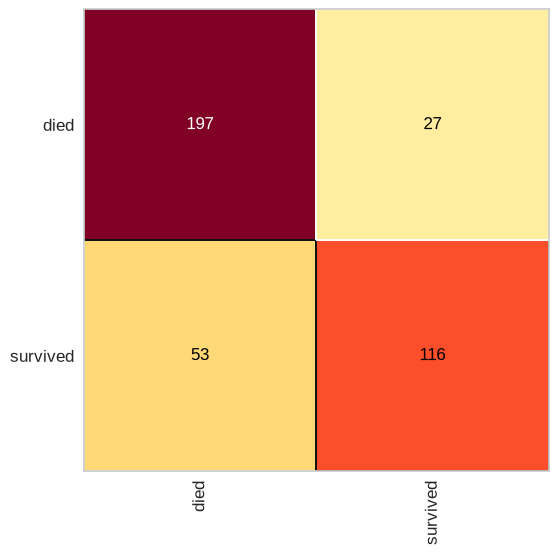

In [129]:
from yellowbrick.classifier import ConfusionMatrix

mapping = {0: "died", 1: "survived"}

fig, ax = plt.subplots(figsize=(6,6))

cm_viz = ConfusionMatrix(
    rf5,
    classes=["died", "survived"],
    label_encoder=mapping,
    force_model=True,
    ax=ax,
    is_fitted=True
)

cm_viz.score(X_test, y_test)

fig.savefig("images/mplr_0304.png", dpi=300, bbox_inches="tight")

In [130]:
from yellowbrick.classifier import ROCAUC

# Curva ROC y AUC

/home/gjae/miniconda3/envs/venv/lib/python3.15/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


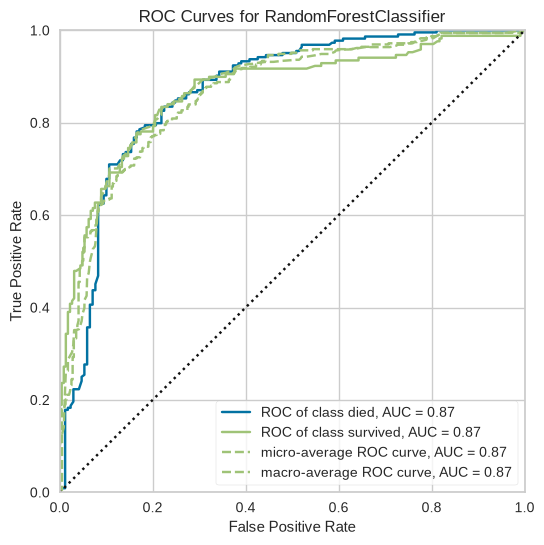

<Axes: title={'center': 'ROC Curves for RandomForestClassifier'}, xlabel='False Positive Rate', ylabel='True Positive Rate'>

In [131]:
fig, ax = plt.subplots(figsize=(6,6))

roc_viz = ROCAUC(rf_random, classes=["died", "survived"], ax=ax, force_model=True)

roc_viz.fit(X_train, y_train)
roc_viz.score(X_test, y_test)
roc_viz.show()


## Calcular umbral optimo

In [134]:
from sklearn.metrics import roc_curve

# Retorna un array con dos columnas: [P(died), P(survived)]
y_probs = rf_random.predict_proba(X_test)

# Extraemos solo la probabilidad de la clase positiva (survived, índice 1)
prob_survived = y_probs[:, 1]

# Obtenemos las tasas de falsos positivos, verdaderos positivos y sus umbrales asociados
fpr, tpr, thresholds = roc_curve(y_test, prob_survived)

# Índice de Youden: maximiza (Sensibilidad - Falsas Alarmas)
j_scores = tpr - fpr
mejor_idx = np.argmax(j_scores)
mejor_umbral = thresholds[mejor_idx]

print(f"Umbral óptimo según Youden: {mejor_umbral:.4f}")
print(f"En este punto: TPR = {tpr[mejor_idx]:.2%}, FPR = {fpr[mejor_idx]:.2%}")

Umbral óptimo según Youden: 0.2908
En este punto: TPR = 83.43%, FPR = 21.88%


# Calcular TP, FP, TN y FN manualmente

**TP**: (verdadero positivo) Las instancias verdaderas que fueron clasificadas como verdaderas

**TN**: (verdaderos negativos) Las instancias negativas que fueron clasificadas como negativas

---

**FN**: (falsos negativos) Las instancias positivas que fueron clasificadas como negativas

**FP**: (falsos positivos) Las instancias negativas que fueron clasificadas como positivas

Partimos del hecho de que ```y_true``` es un array que contiene las predicciones correctas mientras que ```y_pred``` son las predicciones del modelo y ```len(y_true) == len(y_pred)``` . El 100% de las predicciones del modelo correctas equivale a que exista 1 o 0 en el $i^{th}$ posición de la lista en pocas palabras: ```y_true[i] == y_pred[i]```.

como se evalua un clasificador binario, la lista únicamente contiene 0 y 1, una multiplicación de ```y_true``` y ```y_pred``` realiza una multiplicación posicion a posicion, por ende si ```y_pred[1] == 1``` y ```y_true[1] == 0``` , dicha multiplicación será 0.


In [75]:
def calcular_TP(y_true, y_pred):
    # TP, multiplicamos ambos arrays y se cancelaran las posiciones
    # que en y_true (respuesta esperada) sea 1 y en la misma posición y_pred (predicciones del modelo) sea 0
    # luego se suman todos los 1 en el array y se retorna el total de verdaderos positivos
    true_total = y_true * y_pred
    return np.sum(true_total)

def calcular_TN(y_true, y_pred):
    # TN, se invierten momentaneamente ambos arrays de modo que los negativos (0 en los arrays)
    # se vuelvan positivos , luego se aplica la misma lógica que para los TP
    m = (1-y_true) * (1-y_pred)
    return np.sum(m)

def calcular_FN(y_true, y_pred):
    # FN, se suman los y_true  y se resta del total de verdaderos positivos
    # para conocer el total de falsos negativos
    positivos = np.sum(y_true)
    tp = calcular_TP(y_true, y_pred)
    return positivos - tp

def calcular_FP(y_true, y_test):
    # FP, se invierte y_true y se suma (proceso inverso de FN)
    # luego se restadel total de verdaderos negativos (TN)
    negativos = np.sum(1-y_true)
    tn = calcular_TN(y_true, y_test)
    return negativos - tn

def calcular_TPR(y_true, y_pred):
    tp = calcular_TP(y_true, y_pred)
    fn = calcular_FN(y_true, y_pred)

    return tp / (tp + fn)

def calcular_FPR(y_true, y_pred):
    fp = calcular_FP(y_true, y_pred)
    tn = calcular_TN(y_true, y_pred)

    return fp / (tn + fp)

print("Verdaderos positivos: ", calcular_TP(y_test, rf5.predict(X_test)))
print("Falsos positivos: ", calcular_FP(y_test, rf5.predict(X_test)))

print("Verdaderos negativos: ", calcular_TN(y_test, rf5.predict(X_test)))
print("Falsos negativos: ", calcular_FN(y_test, rf5.predict(X_test)))

print("True-Positive Rate: ", calcular_TPR(y_test, rf5.predict(X_test)))
print("False-Positive Rate: ", calcular_FPR(y_test, rf5.predict(X_test)))

Verdaderos positivos:  116
Falsos positivos:  27
Verdaderos negativos:  197
Falsos negativos:  53
True-Positive Rate:  0.6863905325443787
False-Positive Rate:  0.12053571428571429
